In [1]:
import numpy as np
import uproot as up
import awkward as ak

from qkeras.utils import load_qmodel

from keras.models import load_model
import tensorflow_addons as tfa
import tensorflow as tf

import matplotlib.pyplot as plt
import mplhep; mplhep.style.use("CMS")

2025-07-15 19:46:40.989419: I tensorflow/core/util/port.cc:111] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-07-15 19:46:40.993726: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2025-07-15 19:46:41.022976: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-07-15 19:46:41.023006: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-07-15 19:46:41.023037: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to regi

In [2]:
path = "./output/baseline_lipschitz"

In [3]:
gen_pt = np.load(f"{path}/testing_data/truth_pt_test.npy")
reco_pt = np.load(f"{path}/testing_data/reco_pt_test.npy")

y_true = np.load(f"{path}/testing_data/y_test.npy")

In [4]:
constituents = np.load(f"{path}/testing_data/X_test_constits.npy")
jets = np.load(f"{path}/testing_data/X_test_jets.npy")

In [6]:
# model = load_qmodel(f"{path}/model/saved_model.h5")
# preds = model.predict( [jets, constituents] )

model = load_model(f"{path}/model/saved_model.h5")
preds = model.predict( constituents )

2025-07-15 19:46:54.206342: W tensorflow/core/common_runtime/gpu/gpu_device.cc:2211] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


5319/5319 [==============================] - 5s 836us/step


In [ ]:
b_score = preds[0][:,0]
# c_score = preds[0][:,1]
# l_score = preds[0][:,2]
# g_score = preds[0][:,3]
# tp_score = preds[0][:,4]
# tm_score = preds[0][:,5]
# mu_score = preds[0][:,6]
# el_score = preds[0][:,7]

b_true = y_true[:,0]
# c_true = y_true[:,1]
# l_true = y_true[:,2]
# g_true = y_true[:,3]
# tp_true = y_true[:,4]
# tm_true = y_true[:,5]
# mu_true = y_true[:,6]
# el_true = y_true[:,7]

corr_pt = ( preds[1].reshape(reco_pt.shape) ) * reco_pt

In [117]:
from collections import namedtuple

Jet = namedtuple('Jet', ['reco_pt', 'gen_pt', 'corr_pt', 'b_score', 'b_true'])

In [118]:
jet = Jet(reco_pt=reco_pt, gen_pt=gen_pt, corr_pt=corr_pt, b_score=b_score, b_true=b_true)

In [119]:
mistag = lambda b_thresh: ( np.sum( jet.b_score[jet.b_true == 0] > b_thresh ) / np.sum( jet.b_score > b_thresh ) ) * 100

In [120]:
b_thresholds = np.linspace(0, 1, 101)#[0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99]
mistags = [mistag(t) for t in b_thresholds]

/tmp/ipykernel_3986600/1669429092.py:1: RuntimeWarning: invalid value encountered in scalar divide
  mistag = lambda b_thresh: ( np.sum( jet.b_score[jet.b_true == 0] > b_thresh ) / np.sum( jet.b_score > b_thresh ) ) * 100


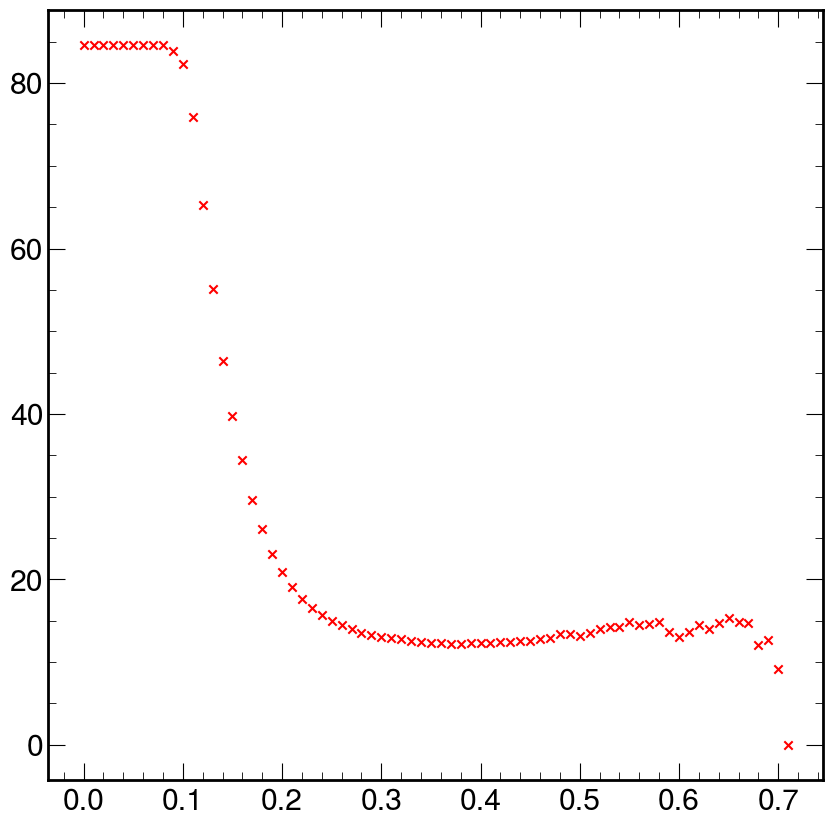

In [121]:
plt.scatter( b_thresholds, mistags, label="Mistag Rate", color="red", marker="x")

In [122]:
def binner(jet, b_thresh):
    pt_bins = np.linspace(0, 400, 21)
    xs = ((pt_bins[1] / 2) + pt_bins)[:-1]  # midpoints of pt bins

    effs = []
    yerrs = []
    count = []
    for b in range(len(pt_bins) - 1):
        mask = (jet.gen_pt >= pt_bins[b]) & (jet.gen_pt < pt_bins[b + 1]) & (jet.b_true == 1)
        
        denom = np.sum(mask)
        count.append(denom)
        numer = np.sum(jet.b_score[mask] > b_thresh)

        eff = numer / denom if denom > 0 else 0
        effs.append(eff)

        # Binomial error
        if denom > 0:
            yerr = np.sqrt(eff * (1 - eff) / denom)
        else:
            yerr = 0
        yerrs.append(yerr)
    
    return xs, effs, yerrs, count

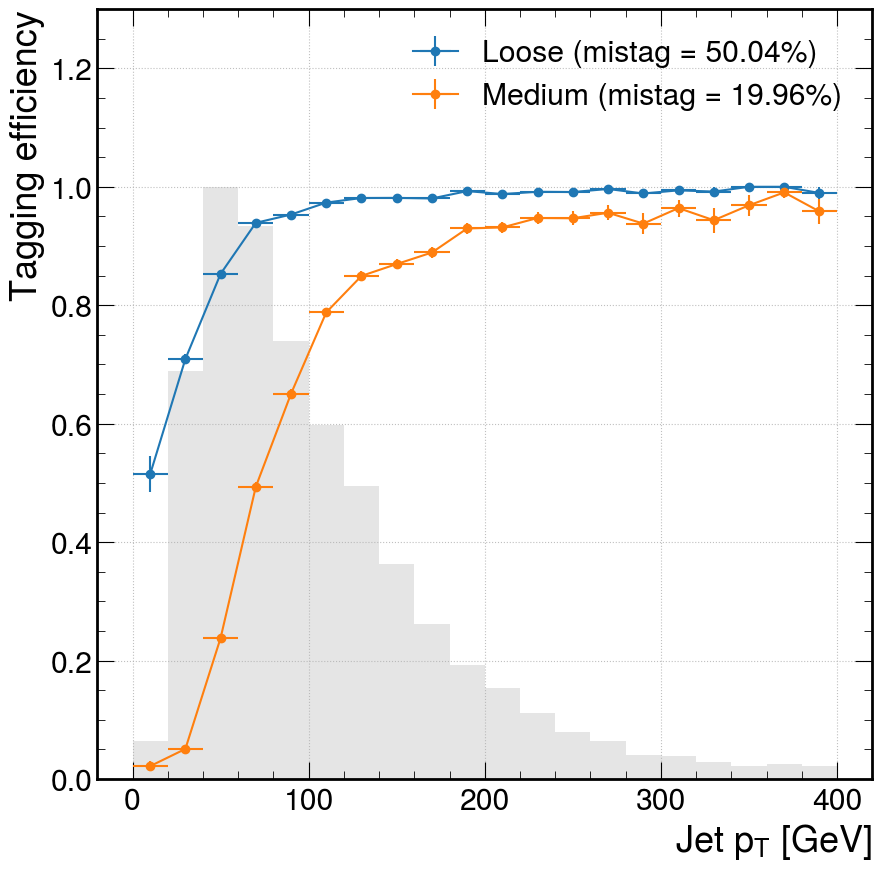

In [123]:
loose = 0.135
medium = 0.205
tight = 0.5

xs, _, _, count = binner(jet, 10)
plt.bar(xs, np.array(count) / max(count), width=2*xs[0], alpha=0.1, color="black")

_, effs, yerrs, _ = binner(jet, loose)
plt.errorbar(xs, effs, xerr=xs[0], yerr=yerrs, fmt="-o", label=f"Loose (mistag = {np.round(mistag(loose), 2)}%)", color="tab:blue")

_, effs, yerrs, _ = binner(jet, medium)
plt.errorbar(xs, effs, xerr=xs[0], yerr=yerrs, fmt="-o", label=f"Medium (mistag = {np.round(mistag(medium), 2)}%)", color="tab:orange")

# _, effs, yerrs, _ = binner(jet, tight)
# plt.errorbar(xs, effs, xerr=xs[0], yerr=yerrs, fmt="-o", label=f"Tight (mistag = {np.round(mistag(tight), 2)}%)", color="tab:green")

plt.ylim([0, 1.3])
plt.xlabel("Jet $p_T$ [GeV]"); plt.ylabel("Tagging efficiency")
plt.legend()
plt.grid()
plt.show()

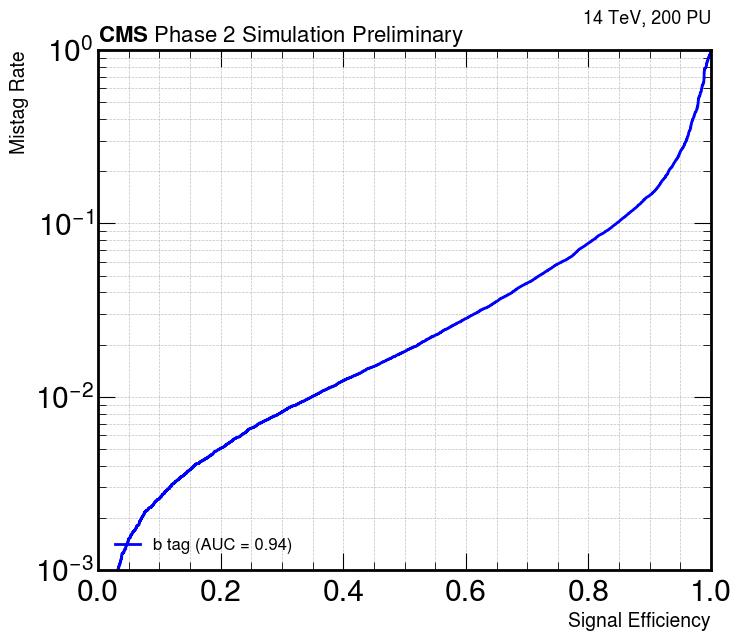

In [110]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Use b_score and b_true
fpr, tpr, _ = roc_curve(jet.b_true, jet.b_score)
roc_auc = auc(fpr, tpr)

# Plot
plt.figure(figsize=(8, 7))
plt.plot(tpr, fpr, lw=2, label=f'b tag (AUC = {roc_auc:.2f})', color='blue')

# CMS-style formatting
plt.xlim([0.0, 1.0])
plt.ylim([1e-3, 1.0])
plt.yscale('log')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.xlabel('Signal Efficiency', fontsize=14)
plt.ylabel('Mistag Rate', fontsize=14)
plt.title(r'$\bf{CMS}$ Phase 2 Simulation Preliminary', fontsize=16, loc='left')
plt.text(1.0, 1.05, '14 TeV, 200 PU', fontsize=13, ha='right', transform=plt.gca().transAxes)
plt.legend(loc='lower left', fontsize=12)

plt.tight_layout()
plt.show()


In [7]:
model = load_model(f"{path}/model/saved_model.h5", custom_objects={'SpectralNormalization': tfa.layers.SpectralNormalization})

In [8]:
perturbed_constits = constituents.copy()

In [9]:
pts = constituents[:,:,0].copy()
samples = np.random.normal(loc=np.mean(pts.flatten()), scale=np.std(pts.flatten()), size=len(pts.flatten())).reshape(pts.shape)
perturbed_constits[:,:,0] = pts * samples

In [ ]:
import numpy as np

def random_swap_along_axis1(arr, swap_prob=0.1, seed=None):
    """
    For each sample n and each axis=1 index i, swap arr[n, i, :] with arr[m, i, :]
    with probability swap_prob, where m != n is random.
    
    Parameters:
        arr: np.ndarray of shape (N, 16, 20)
        swap_prob: float, probability of swapping each entry
        seed: int or None, random seed for reproducibility
    
    Returns:
        new_arr: np.ndarray with swaps performed
    """
    if seed is not None:
        np.random.seed(seed)
    
    N, dim2, dim3 = arr.shape
    new_arr = arr.copy()

    for i in range(dim2):
        # For axis=1 index i, generate random swap mask for each n
        swap_mask = np.random.rand(N) < swap_prob

        # For each n where swap_mask is True, pick a random m != n
        n_indices = np.where(swap_mask)[0]
        if len(n_indices) == 0:
            continue

        # Sample m for each n in n_indices, ensuring m != n
        # We'll do this by sampling random ints from [0, N-2], then shift indices >= n by 1
        random_indices = np.random.randint(0, N - 1, size=len(n_indices))
        m_indices = np.where(random_indices >= n_indices, random_indices + 1, random_indices)

        # Perform swaps between new_arr[n_indices, i, :] and new_arr[m_indices, i, :]
        temp = new_arr[n_indices, i, :].copy()
        new_arr[n_indices, i, :] = new_arr[m_indices, i, :]
        new_arr[m_indices, i, :] = temp

    return new_arr

# Example usage:
# N = 5
# arr = np.arange(N*16*20).reshape(N,16,20).astype(float)
result = random_swap_along_axis1(constituents.copy(), swap_prob=0.25, seed=42)


In [164]:
preds = model.predict(constituents)
preds_perturbed = model.predict(result)

5319/5319 [==============================] - 4s 813us/step


In [165]:
L = np.abs( preds[0][:,0] - preds_perturbed[0][:,0] ) / np.linalg.norm( constituents.reshape(len(constituents), 16*20) - result.reshape(len(result), 16*20), axis=1 )

In [169]:
max(L)

0.026883366419894607

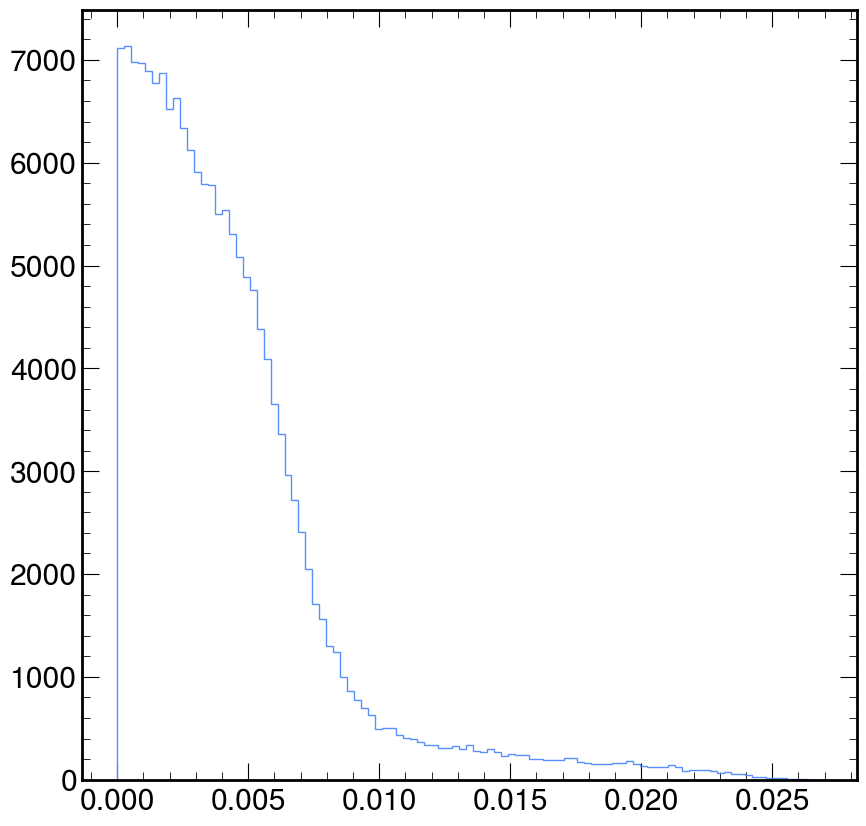

In [167]:
plt.hist(L, bins=101, histtype='step', label='Lipschitz constant')
plt.show()

In [117]:
preds_perturbed[0][:,0]

array([0.1430024 , 0.11672408, 0.10220367, ..., 0.12190647, 0.13535067,
       0.10371444], dtype=float32)

In [104]:
def empirical_lipschitz(model, inputs, output_index=0, n_samples=1000):
    L_vals = []

    for _ in range(n_samples):
        i, j = np.random.choice(len(inputs), 2, replace=False)
        x1 = inputs[i:i+1]
        x2 = inputs[j:j+1]

        y1 = model(x1)[0][:,0].numpy()
        y2 = model(x2)[0][:,0].numpy()
        
        num = np.abs(y1 - y2).squeeze()
        denom = np.linalg.norm(x1.flatten() - x2.flatten())

        if denom > 1e-8:
            L_vals.append(num / denom)

    return L_vals


In [105]:
Ls = empirical_lipschitz(model, constituents, output_index=0, n_samples=10000)

In [145]:
max(Ls)

0.02564008460044423

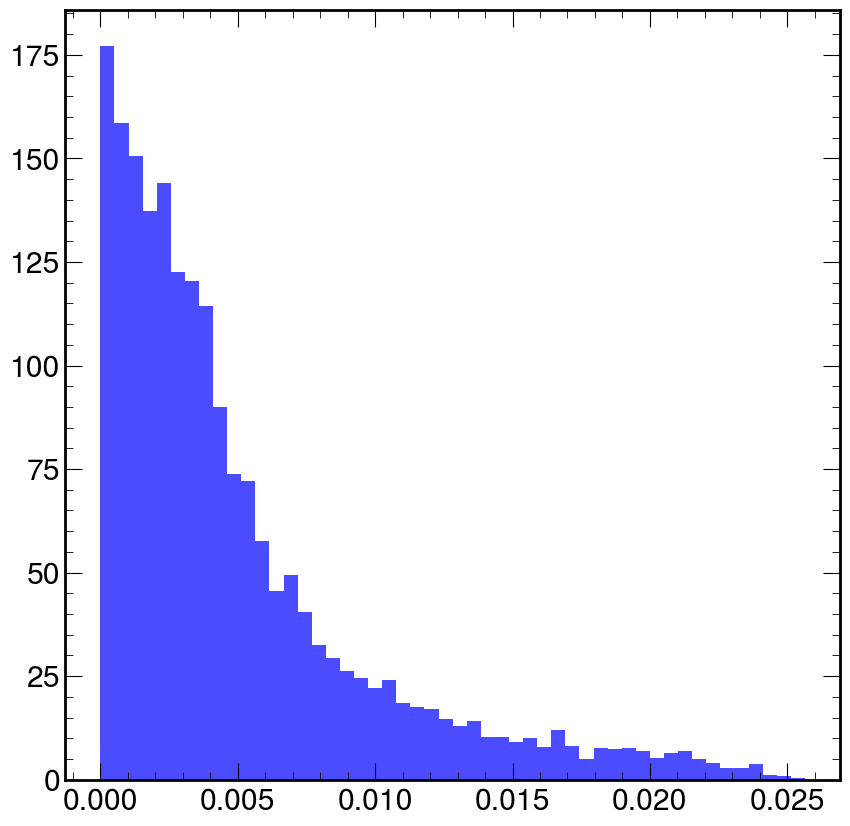

In [106]:
plt.hist(Ls, bins=50, density=True, alpha=0.7, color='blue')
plt.show()

In [12]:
estimate_lipschitz_keras(lipschitz_model, constituents)

Estimating Lipschitz constant for output 0...


(0.019183096,
 [0.004044873,
  0.005052811,
  0.0006873254,
  0.0051428718,
  0.0027564513,
  0.0021559075,
  0.0043833675,
  0.004203282,
  0.0010715156,
  0.0041468497,
  0.0010342752,
  0.0013439216,
  0.0021195265,
  0.0025443684,
  0.00041897557,
  0.005214124,
  0.003791214,
  0.000173725,
  0.0029697486,
  0.0021641946,
  0.00032457098,
  0.002794009,
  0.0004945965,
  0.002580957,
  0.0005422548,
  0.0015078628,
  0.004722898,
  0.0029826262,
  0.0017856992,
  0.005368257,
  0.0023861807,
  0.00033073072,
  0.00068385806,
  0.00021775361,
  0.0017139429,
  0.0014799748,
  0.0020074968,
  0.00094334054,
  0.0016375093,
  0.0017500998,
  0.003541504,
  0.0022451156,
  0.00017190826,
  0.001691461,
  0.00024820966,
  0.0,
  0.0015816775,
  0.0025327916,
  0.003000173,
  0.004561421,
  0.0007022139,
  0.0008513624,
  0.0009172804,
  0.0014818922,
  0.00026699755,
  0.0008350924,
  0.0008532752,
  0.0038679868,
  0.0023223904,
  0.0036461565,
  0.0022068915,
  0.0017735367,
  0.0023

In [ ]:
import numpy as np

def estimate_lipschitz(model, x1, x2, eps=1e-3, num_samples=100):
    lipschitz_vals = []
    for _ in range(num_samples):
        delta = np.random.normal(size=x.shape)
        delta = eps * delta / np.linalg.norm(delta)
        y1 = model([x1,x2])
        y2 = model([x1 + delta, x2+delta])
        diff = np.linalg.norm(y2 - y1) / np.linalg.norm(delta)
        lipschitz_vals.append(diff)
    return max(lipschitz_vals)


In [264]:
empirical_lipschitz(model, jets, constituents)

Estimating Lipschitz:   0%|          | 0/1000 [00:00<?, ?it/s]/software/wq22321/miniconda/envs/tagger/lib/python3.11/site-packages/keras/src/engine/functional.py:642: UserWarning: Input dict contained keys ['jet_input'] which did not match any model input. They will be ignored by the model.
  inputs = self._flatten_to_reference_inputs(inputs)
Estimating Lipschitz: 100%|██████████| 1000/1000 [00:50<00:00, 19.78it/s]


{'max': 0.010529524401644666,
 '95th_percentile': 0.006224763735743467,
 'mean': 0.0013818209416126572,
 'samples': [0.0057299206763580445,
  0.004741869425276146,
  0.00012764760669546602,
  0.00012249316281390748,
  2.195631614240636e-05,
  0.00256691571281881,
  1.80535834336724e-05,
  0.003540974582129746,
  9.674158871630027e-06,
  1.9301116353801674e-06,
  4.223291075391744e-05,
  1.1592995262846709e-05,
  8.6066078159725e-05,
  1.1376780320794145e-05,
  0.001024833322580994,
  0.0021267212626932762,
  0.00029539133318918565,
  3.4316808397915054e-06,
  0.002514231970447651,
  0.0005492647469205714,
  1.06160331531379e-05,
  0.00018787047254821248,
  0.005538442417830162,
  1.2773629299479806e-06,
  9.371258679523567e-06,
  1.6127419037237526e-05,
  1.5626564118602092e-06,
  6.203463020632707e-05,
  1.589911084214425e-05,
  1.2566493723807374e-06,
  0.006911430778916027,
  0.002516473083388382,
  0.00011664301438982543,
  5.1633404815380075e-05,
  0.005190387762366252,
  1.907508

In [ ]:
def estimate_lipschitz_keras(model, jets, constits, output_index=0, num_samples=500, num_perturbations=10, epsilon=1e-5):
    """
    Empirically estimates the L2-Lipschitz constant of a Keras model for a specific output.

    Args:
        model (tf.keras.Model): The trained Keras model.
        data (np.ndarray or tf.Tensor): A batch of input data (e.g., x_test).
        output_index (int): The index of the model output to analyze (0 for jet_id, 1 for pT).
        num_samples (int): The number of data points to use for the estimation.
        num_perturbations (int): How many random perturbations to generate per sample.
        epsilon (float): A small value to control the magnitude of perturbations.

    Returns:
        tuple: (max_ratio, all_ratios) where max_ratio is the estimated L-constant
               and all_ratios is a list of all computed ratios.
    """
    all_ratios = []
    
    # Ensure data is a tf.Tensor
    if not isinstance(jets, tf.Tensor):
        jets = tf.convert_to_tensor(jets, dtype=tf.float32)
        constits = tf.convert_to_tensor(constits, dtype=tf.float32)

    # Randomly select samples from the provided data
    indices = np.random.choice(jets.shape[0], size=num_samples, replace=False)
    sample_data_jets = tf.gather(jets, indices)
    sample_data_constits = tf.gather(constits, indices)

    print(f"Estimating Lipschitz constant for output {output_index}...")

    for i in tf.range(num_samples):
        x_original_jets = sample_data_jets[i:i+1] # Keep the batch dimension
        x_original_constits = sample_data_constits[i:i+1] # Keep the batch dimension
        
        # Get the original model output for the specified branch
        f_original_all_outputs = model([x_original_jets, x_original_constits], training=False)
        f_original = f_original_all_outputs[output_index]

        for _ in range(num_perturbations):
            # Generate a small, random perturbation
            delta_jets = tf.random.normal(shape=x_original_jets.shape, stddev=epsilon)
            x_perturbed_jets = x_original_jets + delta_jets
            delta_constits = tf.random.normal(shape=x_original_constits.shape, stddev=epsilon)
            x_perturbed_constits = x_original_constits + delta_constits

            # Get the perturbed model output
            f_perturbed_all_outputs = model([x_perturbed_jets, x_perturbed_constits], training=False)
            f_perturbed = f_perturbed_all_outputs[output_index]

            # Calculate L2 norms of the change in input and output
            delta_input_norm_jets = tf.norm(delta_jets)
            delta_input_norm_constits = tf.norm(delta_jets)
            delta_output_norm = tf.norm(f_perturbed - f_original)
            
            # Avoid division by zero
            if delta_input_norm_jets > 1e-9:
                ratio = delta_output_norm / delta_input_norm_jets
                all_ratios.append(ratio.numpy())

    if not all_ratios:
        return 0.0, []

    estimated_L = max(all_ratios)
    return estimated_L, all_ratios